In [97]:
# %pip install opencv-python matplotlib scikit-learn pandas seaborn kagglehub

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
import random

from collections import Counter
from pathlib import Path

import kagglehub

# Download latest version
path = kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes")

data_path  = Path(path)

# train_path = data_path / "Train"


100%|██████████| 133M/133M [00:10<00:00, 13.5MB/s] 

Extracting files...


In [98]:
# print(list(train_path.iterdir()))

In [99]:
for split_path in data_path.iterdir():
    print(f"\n{split_path.name}")
    for class_path in split_path.iterdir():
        print(f"{class_path.name}")
        if class_path.is_dir():
            for sub_path in class_path.iterdir():
                print(f" {sub_path.name}")


Train
Glioma
 images
 labels
Meningioma
 images
 labels
No Tumor
 images
 labels
Pituitary
 images
 labels

Val
Glioma
 images
 labels
Meningioma
 images
 labels
No Tumor
 images
 labels
Pituitary
 images
 labels


In [100]:
for sub_path in sorted(data_path.iterdir()):
    if not sub_path.is_dir():
        continue
    print(f"\n{'=' * 40}")
    print(f"{sub_path.name}")

    for class_path in sorted(split_path.iterdir()):
        if not class_path.is_dir():
            continue
        images_path = class_path / "images"
        labels_path = class_path / "labels"

        if images_path.exists() and labels_path.exists():
            images = [
                p for p in images_path.iterdir()
                if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
            ]

            labels = list(labels_path.glob("*.txt"))

            print(
                f"{class_path.name}: "
                f"{len(images)} images | {len(labels)} labels"
            )


Train
Glioma: 136 images | 136 labels
Meningioma: 140 images | 140 labels
No Tumor: 100 images | 100 labels
Pituitary: 136 images | 136 labels

Val
Glioma: 136 images | 136 labels
Meningioma: 140 images | 140 labels
No Tumor: 100 images | 100 labels
Pituitary: 136 images | 136 labels


In [101]:
for split_name in ["Train" , "Val"]:
    split_path = data_path / split_name
    
    for class_name in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        labels_path = split_path / class_name / "labels"
        label_files = sorted(labels_path.glob("*.txt"))

        if label_files:
            label_file = label_files[0]

            print(f"\nSplit: {split_name}")
            print(f"Class: {class_name}")
            print(f"File: {label_file.name}")
            print(label_file.read_text())


Split: Train
Class: Glioma
File: Te-glTr_0000.txt
0 0.555664 0.653320 0.146484 0.193359


Split: Train
Class: Meningioma
File: Tr-meTr_0008.txt
1 0.313477 0.631836 0.193359 0.240234


Split: Train
Class: No Tumor
File: 1.txt
2 0.502857 0.675714 0.851429 0.648571


Split: Train
Class: Pituitary
File: Te-pi_0010.txt
3 0.494141 0.431641 0.046875 0.039062


Split: Val
Class: Glioma
File: Tr-gl_0202.txt
0 0.370117 0.284180 0.154297 0.208984


Split: Val
Class: Meningioma
File: Tr-meTr_0000.txt
1 0.630859 0.467773 0.218750 0.119141


Split: Val
Class: No Tumor
File: Tr-no_0025.txt
2 0.505656 0.504525 0.653846 0.760181


Split: Val
Class: Pituitary
File: Te-pi_0018.txt
3 0.496094 0.408203 0.062500 0.066406



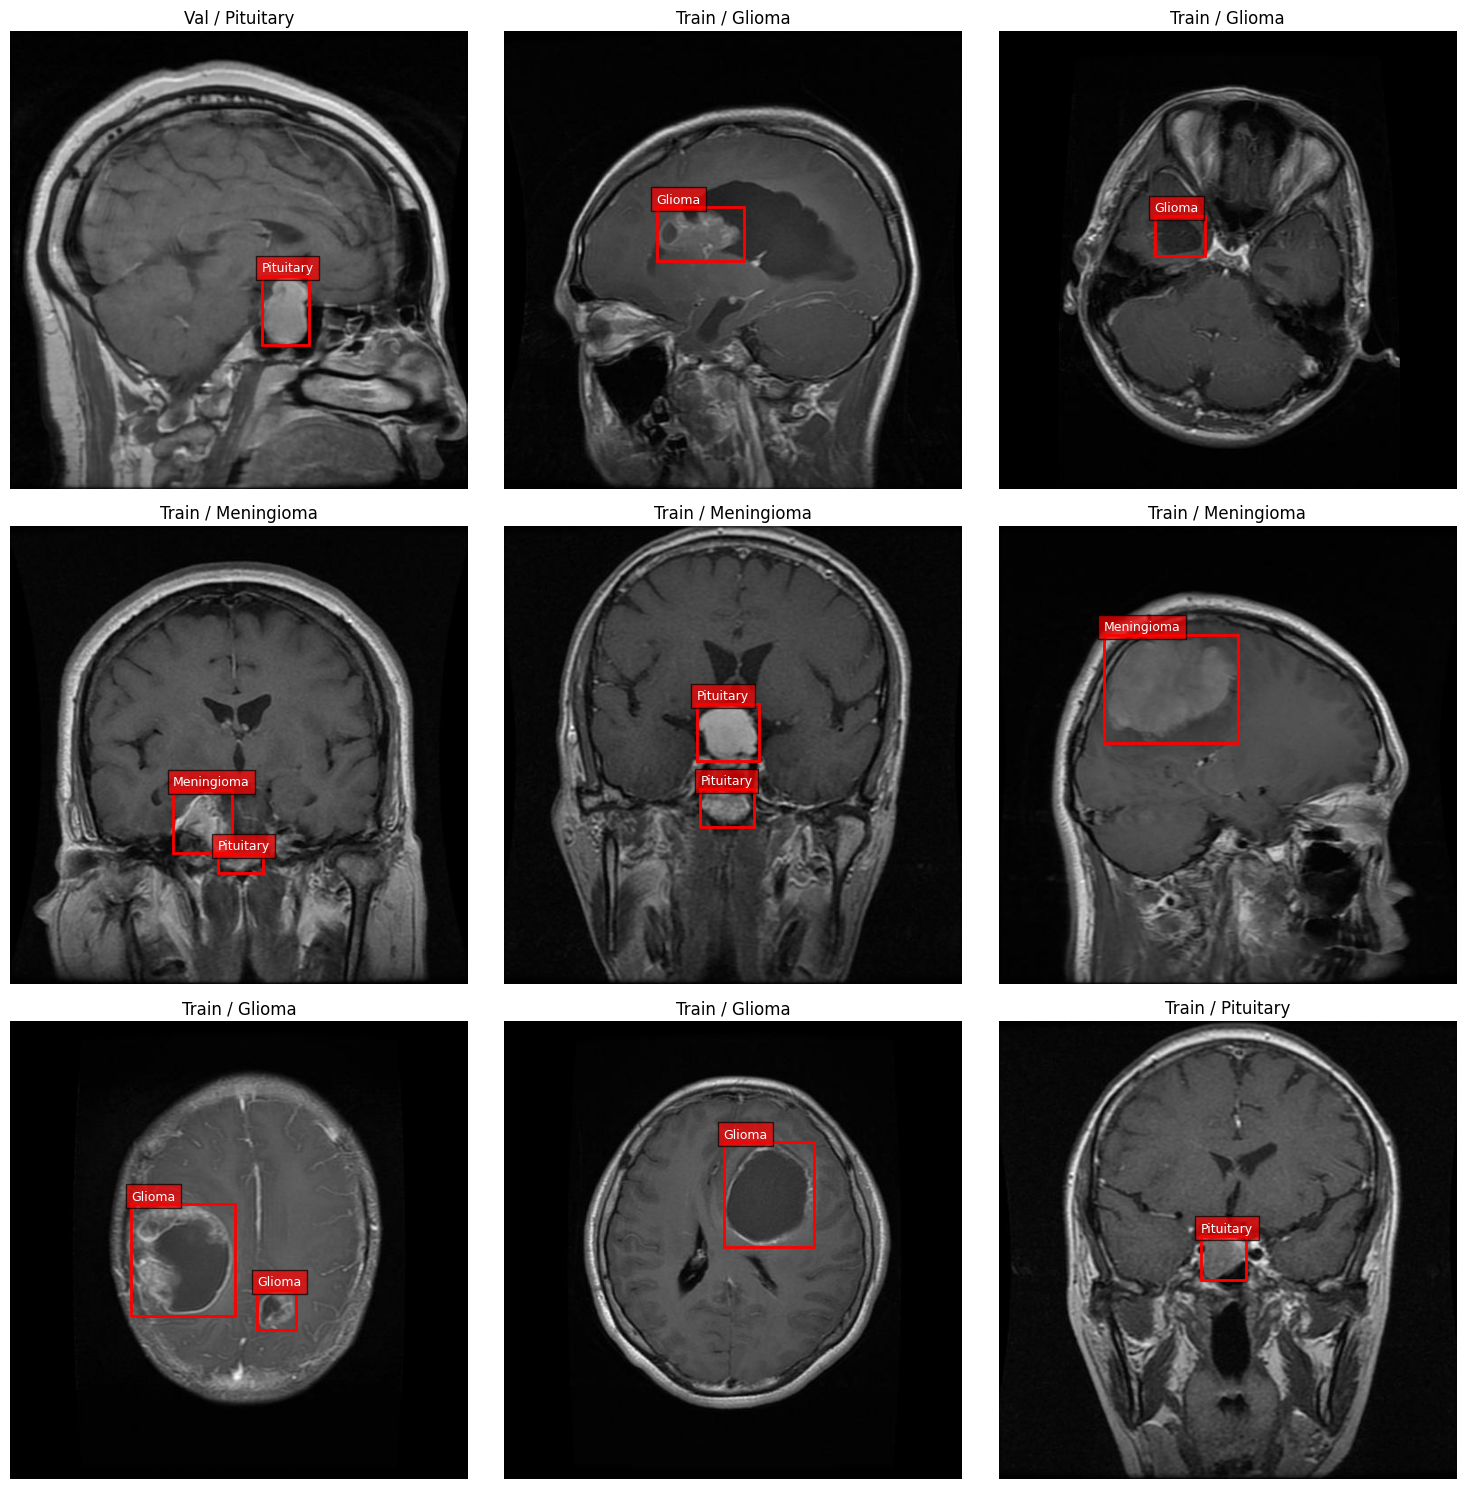

In [102]:
class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}

image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

samples = []

for split_name in ["Train", "Val"]:
    split_path = data_path / split_name

    for class_name in class_names.values():
        images_path = split_path / class_name / "images"

        for image_path in images_path.iterdir():
            if image_path.suffix.lower() in image_extensions:
                samples.append(image_path)

random.seed(42)

samples = random.sample(samples, min(9, len(samples)))

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ax, image_path in zip(axes.flat, samples):
    image = cv2.imread(image_path)

    if image is None:
        ax.set_title(f"can not read: {image_path.name}")
        ax.axis("off")
        continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    label_path = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"

    ax.imshow(image)

    if label_path.exists():
        lines = label_path.read_text().strip().splitlines()

        for line in lines:
            values = line.split()

            # print(values)

            if len(values) != 5:
                continue

            class_id, x_center, y_center, box_width, box_height = (
                int(values[0]),
                float(values[1]),
                float(values[2]),
                float(values[3]),
                float(values[4]),
            )

            x_center *= width
            y_center *= height
            box_width *= width
            box_height *= height

            x_min = x_center - box_width / 2
            y_min = y_center - box_height / 2

            rect = plt.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )

            ax.add_patch(rect)

            class_name = class_names.get(class_id, f"unknow {class_id}")

            ax.text(
                x_min,
                max(0, y_min - 5),
                class_name,
                color="white",
                fontsize=9,
                bbox=dict(facecolor="red", alpha=0.7),
            )

    ax.set_title(
        image_path.parent.parent.parent.name + " / " + image_path.parent.parent.name
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


In [103]:
class_stats = []

for split_name in ['Train' , "Val"]:
    split_path = data_path / split_name

    for class_id , class_name in class_names.items():
        labels_path = split_path / class_name / "labels"
        images_path = split_path / class_name / "images"

        image_count = 0
        box_count = 0

        for image_path in images_path.iterdir():
            if image_path.suffix.lower() not in image_extensions:
                continue
            image_count += 1
            label_path = labels_path / f"{image_path.stem}.txt"

            if label_path.exists():
                lines = label_path.read_text().splitlines()
                box_count += sum(1 for line in lines if line.split())

        class_stats.append({
            "Split": split_name,
            "Class": class_name,
            "Images": image_count,
            "Bounding Boxes": box_count
        })
stats_df = pd.DataFrame(class_stats)

display(stats_df)

,Split,Class,Images,Bounding Boxes
0,Train,Glioma,1153,1502
1,Train,Meningioma,1449,1583
2,Train,No Tumor,711,711
3,Train,Pituitary,1424,1521
4,Val,Glioma,136,165
5,Val,Meningioma,140,148
6,Val,No Tumor,100,98
7,Val,Pituitary,136,143


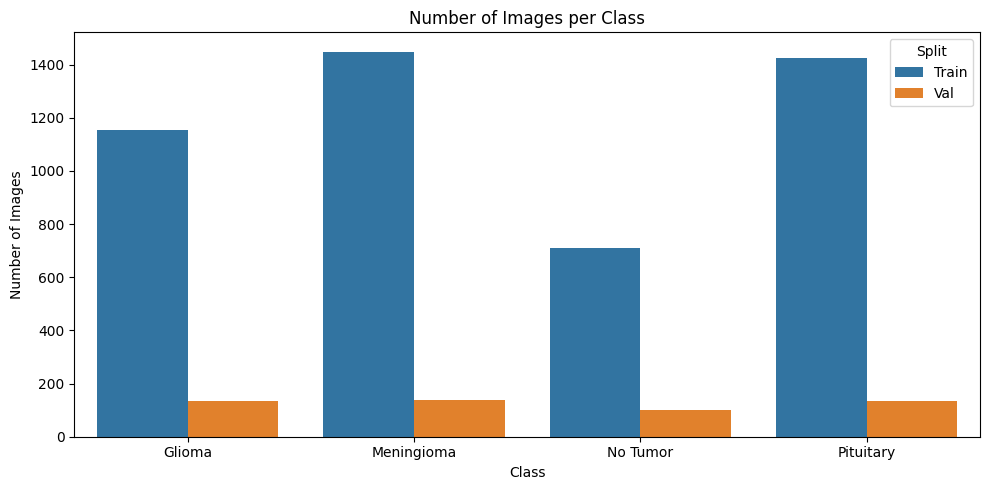

In [104]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=stats_df,
    x="Class",
    y="Images",
    hue="Split",
)

plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

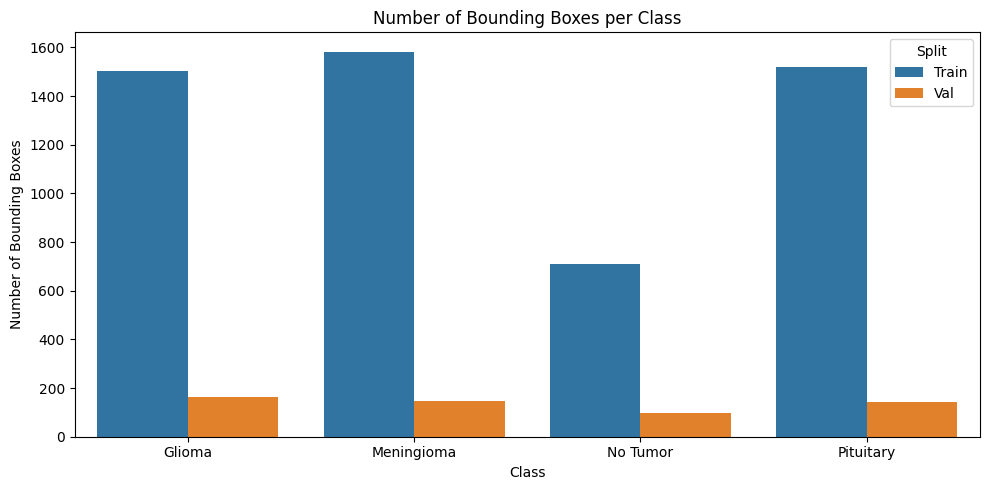

In [105]:
plt.figure(figsize=(10, 5))

sns.barplot(data=stats_df, x="Class", y="Bounding Boxes", hue="Split")

plt.title("Number of Bounding Boxes per Class")
plt.xlabel("Class")
plt.ylabel("Number of Bounding Boxes")
plt.tight_layout()
plt.show()

In [106]:
splits = ["Train", "Val"]
classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

issues = []

for split in splits:
    for class_name in classes:
        class_path = data_path / split / class_name
        images_path = class_path / "images"
        labels_path = class_path / "labels"

        images = {
            file.stem: file
            for file in images_path.iterdir()
            if file.suffix.lower() in image_extensions
        }

        labels = {file.stem: file for file in labels_path.glob("*.txt")}

        for name in images.keys() - labels.keys():
            issues.append(f"Missing label: {split}/{class_name}/{name}")

        for name in labels.keys() - images.keys():
            issues.append(f"Missing image: {split}/{class_name}/{name}")

        for name, image_path in images.items():
            image = cv2.imread(str(image_path))

            if image is None:
                issues.append(f"Unreadable image: {image_path}")
                continue
            label_path = labels_path / f"{name}.txt"

            if not label_path.exists():
                continue
            for line_number, line in enumerate(
                label_path.read_text().splitlines(), start=1
            ):
                values = line.split()

                if len(values) != 5:
                    issues.append(
                        f"Invalid label format: {label_path}, line {line_number}"
                    )
                    continue
                try:
                    class_id, x, y, w, h = map(float, values)
                except ValueError:
                    issues.append(
                        f"Non-numeric label: {label_path}, line {line_number}"
                    )

                    continue
                if (
                    not class_id.is_integer()
                    or class_id not in range(4)
                    or not all(0 <= v <= 1 for v in [x, y, w, h])
                    or w <= 0
                    or h <= 0
                ):
                    issues.append(
                        f"Invalid coordinates/class: {label_path}, line {line_number}"
                    )

print(f"Total issues found: {len(issues)}")

for issue in issues[:30]:
    print(issue)

if len(issues) > 30:
    print(f"... and {len(issues) - 30} more issues.")


Total issues found: 4
Missing label: Val/No Tumor/image(55)
Missing label: Val/No Tumor/image(61)
Missing image: Val/No Tumor/image(60)
Missing image: Val/No Tumor/image(53)


In [107]:
images_path = data_path / "Val" / "No Tumor" / "images"
labels_path = data_path / "Val" / "No Tumor" / "labels"

files_to_remove = [
    images_path / "image(55).jpg",
    images_path / "image(61).jpg",
    labels_path / "image(53).txt",
    labels_path / "image(60).txt",
]

for file in files_to_remove:
    if file.exists():
        file.unlink()